#Parasitic Platform AI Model

Pongphan Pongpanitanont

---

Health Sciences, Biomedical Engineering, Medical Technology

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!mkdir dataset
!unzip -q /content/drive/MyDrive/ov_images/ov-mif_d1d2.zip -d dataset

In [ ]:
path = "/content/drive/MyDrive/parasitic_platform/"

##Classification Model with Dataset 1

###Import Dataset

In [ ]:
import os
from PIL import Image

def loadimages(folder):
  images = []
  for filename in os.listdir(folder):
    img = Image.open(os.path.join(folder,filename))
    if img is not None:
      images.append(img)
  return images

In [ ]:
class0 = loadimages("/content/dataset/class0_d1")
class1 = loadimages("/content/dataset/class1_d1")
class2 = loadimages("/content/dataset/class2_d1")

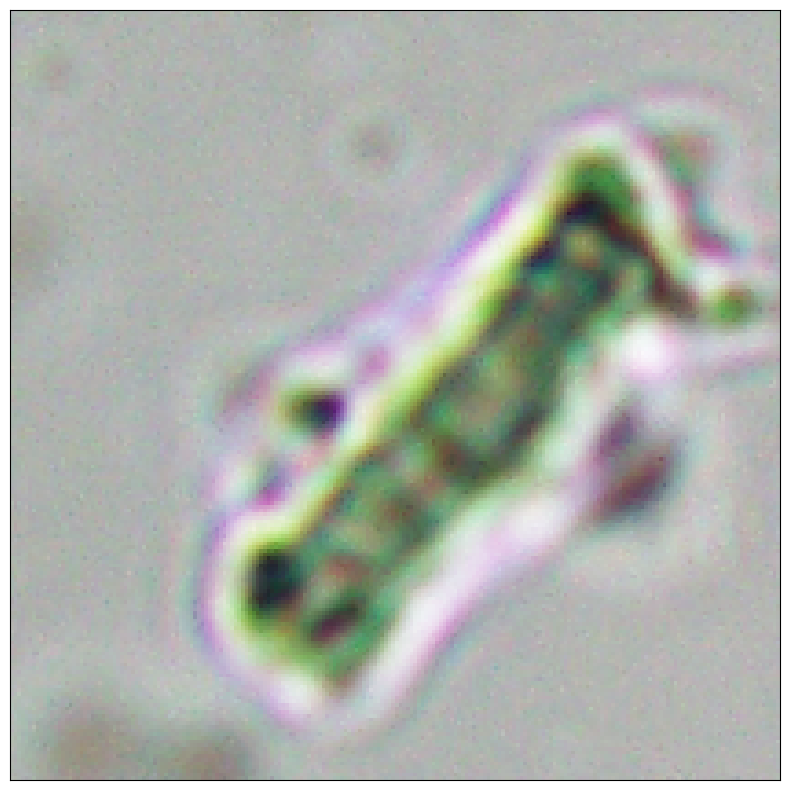

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class0[i], cmap = plt.cm.binary)
plt.show()

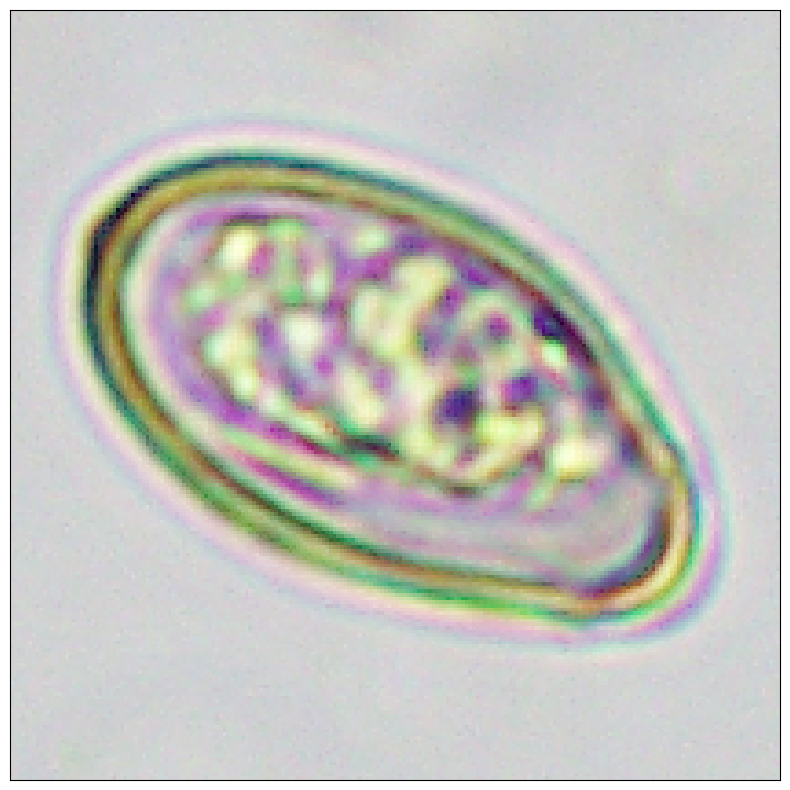

In [ ]:
plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class1[i], cmap = plt.cm.binary)
plt.show()

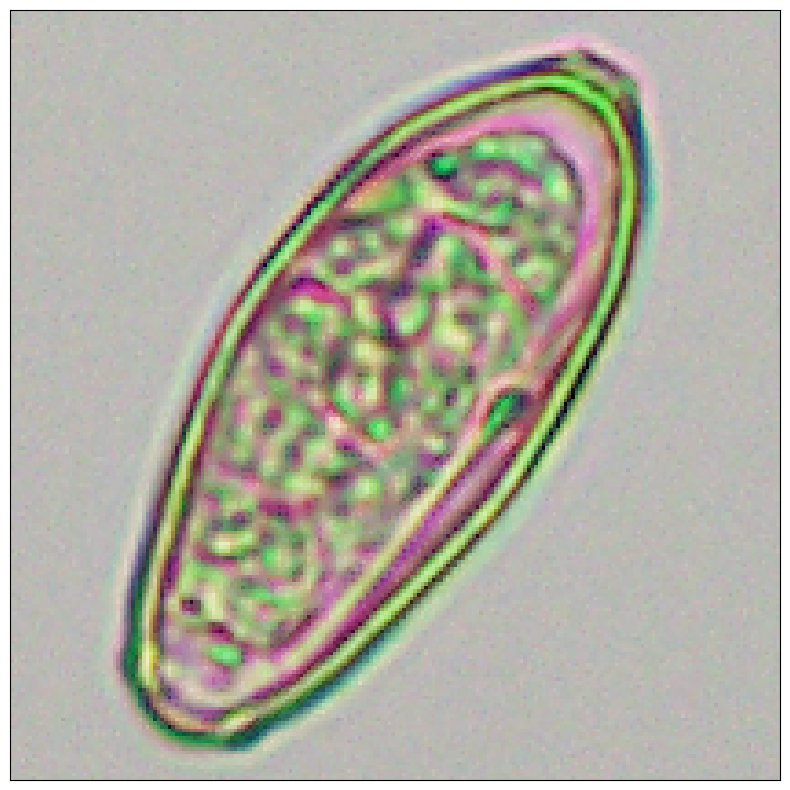

In [ ]:
plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class2[i], cmap = plt.cm.binary)
plt.show()

In [ ]:
print(f"class0 shape: {class0[0].size}")
print(f"class0 shape: {class0[1].size}")
print(f"class0 shape: {class0[2].size}")

class0 shape: (210, 210)
class0 shape: (210, 210)
class0 shape: (210, 210)


In [ ]:
print(f"num class0: {len(class0)}")
print(f"num class1: {len(class1)}")
print(f"num class2: {len(class2)}")

num class0: 500
num class1: 500
num class2: 500


In [ ]:
class0_label = [0] * len(class0)
class1_label = [1] * len(class1)
class2_label = [2] * len(class2)

In [ ]:
from sklearn.model_selection import train_test_split

x_train_class0, x_test_class0, y_train_class0, y_test_class0 = train_test_split(class0, class0_label, test_size=0.2, random_state=8)
x_train_class1, x_test_class1, y_train_class1, y_test_class1 = train_test_split(class1, class1_label, test_size=0.2, random_state=8)
x_train_class2, x_test_class2, y_train_class2, y_test_class2 = train_test_split(class2, class2_label, test_size=0.2, random_state=8)

In [ ]:
x_train=[]

for i in x_train_class0:
  x_train.append(i)
for i in x_train_class1:
  x_train.append(i)
for i in x_train_class2:
  x_train.append(i)

In [ ]:
x_test=[]

for i in x_test_class0:
  x_test.append(i)
for i in x_test_class1:
  x_test.append(i)
for i in x_test_class2:
  x_test.append(i)

In [ ]:
y_train=[]

for i in y_train_class0:
  y_train.append(i)
for i in y_train_class1:
  y_train.append(i)
for i in y_train_class2:
  y_train.append(i)

In [ ]:
y_test=[]

for i in y_test_class0:
  y_test.append(i)
for i in y_test_class1:
  y_test.append(i)
for i in y_test_class2:
  y_test.append(i)

In [ ]:
print(f"num x_train: {len(x_train)}")
print(f"num x_test: {len(x_test)}")
print(f"num y_train: {len(y_train)}")
print(f"num y_test: {len(y_test)}")

num x_train: 1200
num x_test: 300
num y_train: 1200
num y_test: 300


###Data Augmentation

In [ ]:
from PIL import Image
import numpy as np

def imrotation(img, angle):
  if isinstance(img, np.ndarray):
    img = Image.fromarray(img)

  rotate_img = img.rotate(-angle, expand=False)
  rotate_img = np.array(rotate_img)

  return rotate_img[:, :, 0:3]

In [ ]:
from PIL import ImageEnhance

def brightness(img, value):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  enhancer = ImageEnhance.Brightness(pil_img)
  factor = 1.0 + (value / 255.0)
  brightened_image = enhancer.enhance(factor)

  return np.array(brightened_image)

In [ ]:
def histeq(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  img_float = img_array.astype(np.float32)
  yuv = np.dot(img_float, [[0.299, -0.168736, 0.5], [0.587, -0.331264, -0.418688], [0.114, 0.5, -0.081312]])
  yuv[:,:,1:] += 128.0

  y_channel = yuv[:,:,0].astype(np.uint8)
  pil_y = Image.fromarray(y_channel)
  equalized_y = np.array(pil_y.point(lambda x: _get_equalization_lut()[x]))
  yuv[:,:,0] = equalized_y

  yuv[:,:,1:] -= 128.0
  rgb = np.dot(yuv, [[1.0, 1.0, 1.0], [0.0, -0.394642, 2.03211], [1.13983, -0.58062, 0.0]])
  rgb = np.clip(rgb, 0, 255).astype(np.uint8)

  return Image.fromarray(rgb)

def _get_equalization_lut():
  return list(range(256))

In [ ]:
from PIL import ImageFilter

def averaging(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  image = pil_img.filter(ImageFilter.BoxBlur(2.5))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
def addgaussian(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  r, g, b = img_array[:, :, 0], img_array[:, :, 1], img_array[:, :, 2]

  mean = 0
  sd = 1

  r_noise = np.random.normal(mean, sd, r.shape).astype(np.uint8)
  g_noise = np.random.normal(mean, sd, g.shape).astype(np.uint8)
  b_noise = np.random.normal(mean, sd, b.shape).astype(np.uint8)

  r = np.clip(r.astype(np.int16) + r_noise, 0, 255).astype(np.uint8)
  g = np.clip(g.astype(np.int16) + g_noise, 0, 255).astype(np.uint8)
  b = np.clip(b.astype(np.int16) + b_noise, 0, 255).astype(np.uint8)

  img_array = np.stack([r, g, b], axis=2)
  image = Image.fromarray(img_array)
  return image

In [ ]:
from PIL import Image, ImageFilter
import numpy as np

def sharpening(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  kernel = [-1, -1, -1, -1,  9, -1, -1, -1, -1]

  image = pil_img.filter(ImageFilter.Kernel((3, 3), kernel))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
x_train_temp = []
y_train_temp = []

for i in range(len(x_train)):
  current_img_np = np.array(x_train[i])

  for j in range(0,360,90):
    image_r = imrotation(current_img_np, j)

    x_train_temp.append(image_r)
    y_train_temp.append(y_train[i])

    x_train_temp.append(brightness(image_r, 50))
    y_train_temp.append(y_train[i])

    x_train_temp.append(histeq(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(averaging(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(addgaussian(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(sharpening(image_r))
    y_train_temp.append(y_train[i])

x_train = x_train_temp
y_train = y_train_temp

In [ ]:
print(f"x_train: {len(x_train)}")
print(f"y_train: {len(y_train)}")

x_train: 28800
y_train: 28800


###Model Training and Validation

In [ ]:
from keras.utils import to_categorical

y_train_cat = to_categorical(y_train)

In [ ]:
size = (128,128)

for i in range(len(x_train)):
  if isinstance(x_train[i], np.ndarray):
    x_train[i] = Image.fromarray(x_train[i])
  x_train[i] = x_train[i].resize(size)
  x_train[i] = np.array(x_train[i])

for i in range(len(x_test)):
  if isinstance(x_test[i], np.ndarray):
    x_test[i] = Image.fromarray(x_test[i])
  x_test[i] = x_test[i].resize(size)
  x_test[i] = np.array(x_test[i])

In [ ]:
import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
EPOCH = 50

####Model PACA

In [5]:
from tensorflow.keras import layers, Model

def conv_block(x, filters, k=3, s=1):
  x = layers.Conv2D(filters, k, strides=s, padding="same", use_bias=False)(x)
  x = layers.BatchNormalization()(x)
  x = layers.Activation("relu")(x)
  return x

def paca_model(img_size):
  inp = layers.Input(shape=(img_size, img_size, 3))

  a = conv_block(inp, 32); a = layers.MaxPool2D()(a)
  a = conv_block(a, 64);  a = layers.MaxPool2D()(a)
  a = conv_block(a, 128); a = layers.MaxPool2D()(a)
  a = conv_block(a, 256)
  a = layers.GlobalAveragePooling2D()(a)

  b = layers.Conv2D(96, kernel_size=4, strides=4, padding="same")(inp)
  b = layers.Reshape((-1, 96))(b)
  b = layers.LayerNormalization()(b)

  attn = layers.MultiHeadAttention(num_heads=4, key_dim=24, dropout=0.1)(b, b)
  b = layers.Add()([b, attn])
  b = layers.LayerNormalization()(b)

  ffn = layers.Dense(192, activation="relu")(b)
  ffn = layers.Dropout(0.1)(ffn)
  ffn = layers.Dense(96)(ffn)
  b = layers.Add()([b, ffn])
  b = layers.LayerNormalization()(b)

  b = layers.GlobalAveragePooling1D()(b)

  x = layers.Concatenate()([a, b])
  x = layers.Dense(256, activation="relu")(x)
  x = layers.Dropout(0.35)(x)
  x = layers.Dense(64, activation="relu")(x)
  x = layers.Dropout(0.25)(x)
  out = layers.Dense(3, activation="sigmoid")(x)

  model = Model(inp, out, name="PACA")
  return model

#model = paca_model(x_train[0].shape[0])
model = paca_model(128)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "PACA"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 128, 128,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     18,432 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │      4,704 │ input_layer_1[0]… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1024, 96)  │          0 │ conv2d_16[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 1024, 96)  │        192 │ reshape[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 1024, 96)  │     37,248 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │     73,728 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1024, 96)  │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 1024, 96)  │        192 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 576,547 (2.20 MB)

 Trainable params: 575,587 (2.20 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 104s 23ms/step - accuracy: 0.9439 - loss: 0.1593 - val_accuracy: 0.7851 - val_loss: 0.5671
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9813 - loss: 0.0624 - val_accuracy: 0.7726 - val_loss: 0.5966
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9883 - loss: 0.0363 - val_accuracy: 0.0545 - val_loss: 8.3445
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9912 - loss: 0.0299 - val_accuracy: 0.9941 - val_loss: 0.0145
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9932 - loss: 0.0216 - val_accuracy: 0.9851 - val_loss: 0.0447
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9936 - loss: 0.0218 - val_accuracy: 0.9882 - val_loss: 0.0284
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9943 - loss: 0.0189 - val_accuracy: 0.9524 - val_loss: 0.0987
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9964 

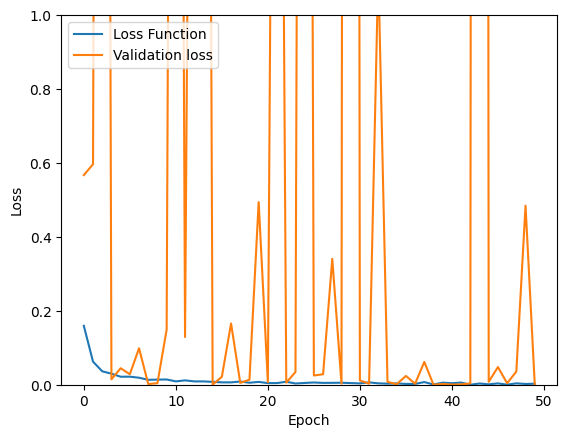

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

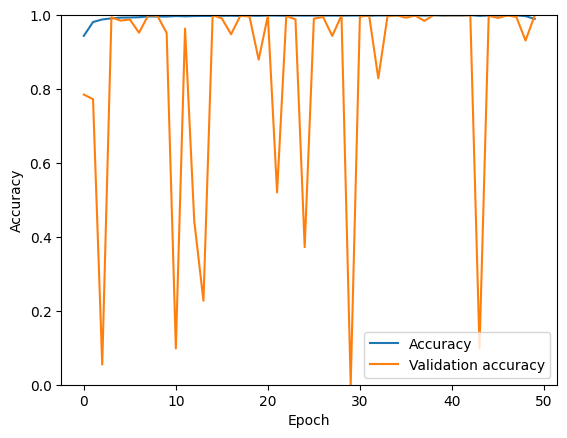

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 966ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  1   0  99]]
--------------------------
Accuracy: 0.9966666666666667
Precision: 0.9966996699669968
Recall: 0.9966666666666667
F1 score: 0.99666658333125


In [ ]:
model.save(path + "paca_d1.keras")

####Model CNN

In [2]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential()

#model.add(Conv2D(64, (3, 3), activation = 'relu', input_shape = (x_train[0].shape)))
model.add(Conv2D(64, (3, 3), activation = 'relu', input_shape = (128,128,3)))

model.add(Conv2D(64, (3, 3), activation = 'relu'))
model.add(Conv2D(64, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(128, activation = 'relu'))
model.add(Dense(64, activation = 'relu'))
model.add(Dense(32, activation = 'relu'))
model.add(Dense(16, activation = 'relu'))
model.add(Dense(8, activation = 'relu'))
model.add(Dense(3, activation = 'sigmoid'))

model.compile(optimizer = 'sgd', loss = 'mse', metrics = ['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 124, 124, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 122, 122, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 59, 59, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 57, 57, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 55, 55, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 27, 27, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 25, 25, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 23, 23, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 6, 6, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 2, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,451 (544.73 KB)

 Trainable params: 139,451 (544.73 KB)

 Non-trainable params: 0 (0.00 B)

Model Training

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 14ms/step - accuracy: 0.6892 - loss: 0.1406 - val_accuracy: 0.9722 - val_loss: 0.0187
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9414 - loss: 0.0312 - val_accuracy: 0.9715 - val_loss: 0.0161
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9679 - loss: 0.0176 - val_accuracy: 0.9448 - val_loss: 0.0293
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9796 - loss: 0.0109 - val_accuracy: 0.9924 - val_loss: 0.0045
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9833 - loss: 0.0090 - val_accuracy: 0.9684 - val_loss: 0.0175
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9889 - loss: 0.0062 - val_accuracy: 0.9937 - val_loss: 0.0032
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9914 - loss: 0.0048 - val_accuracy: 0.9920 - val_loss: 0.0046
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9919 -

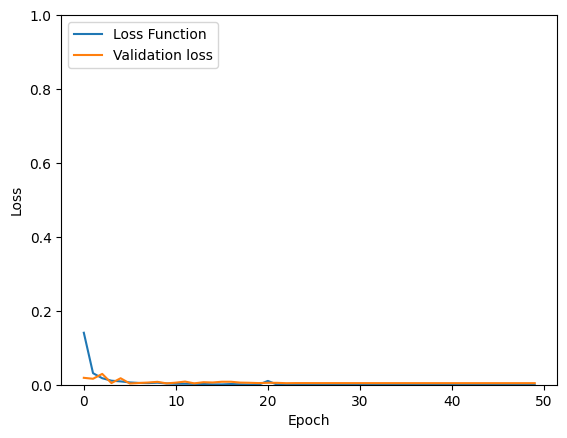

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

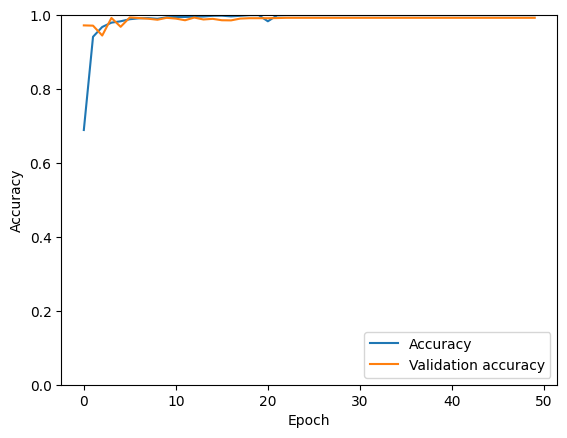

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 400ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[ 96   0   4]
 [  0 100   0]
 [  0   1  99]]
--------------------------
Accuracy: 0.9833333333333333
Precision: 0.9837546861482266
Recall: 0.9833333333333333
F1 score: 0.9833287234948879


In [ ]:
model.save(path + "cnn_d1.keras")

##Classification Model with Dataset 2

###Import Dataset

In [ ]:
import os
from PIL import Image

def loadimages(folder):
  images = []
  for filename in os.listdir(folder):
    img = Image.open(os.path.join(folder,filename))
    if img is not None:
      images.append(img)
  return images

In [ ]:
class0 = loadimages("/content/dataset/class0_d2")
class1 = loadimages("/content/dataset/class1_d2")
class2 = loadimages("/content/dataset/class2_d2")

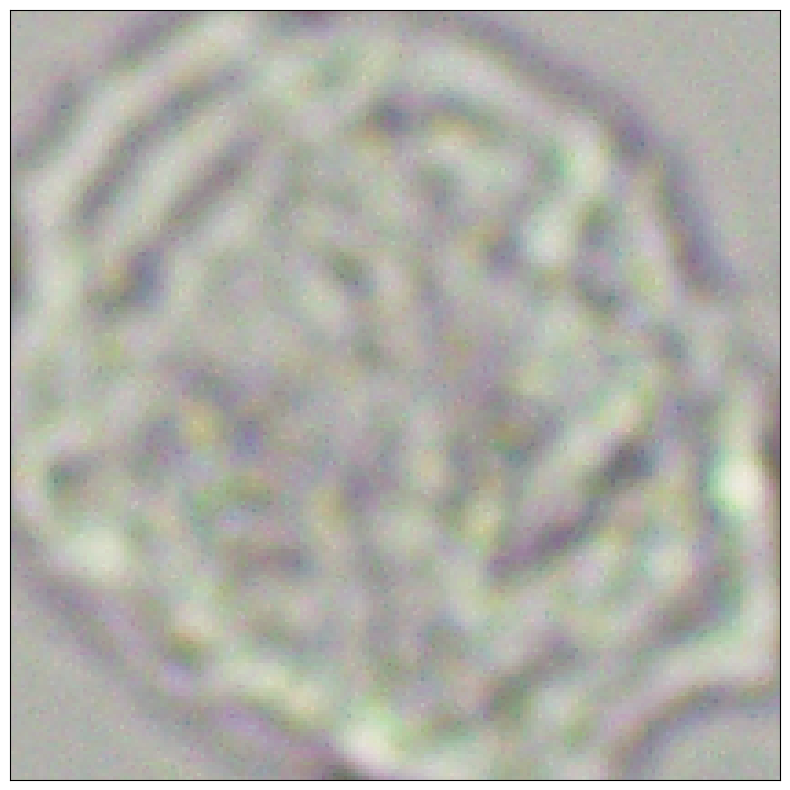

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class0[i], cmap = plt.cm.binary)
plt.show()

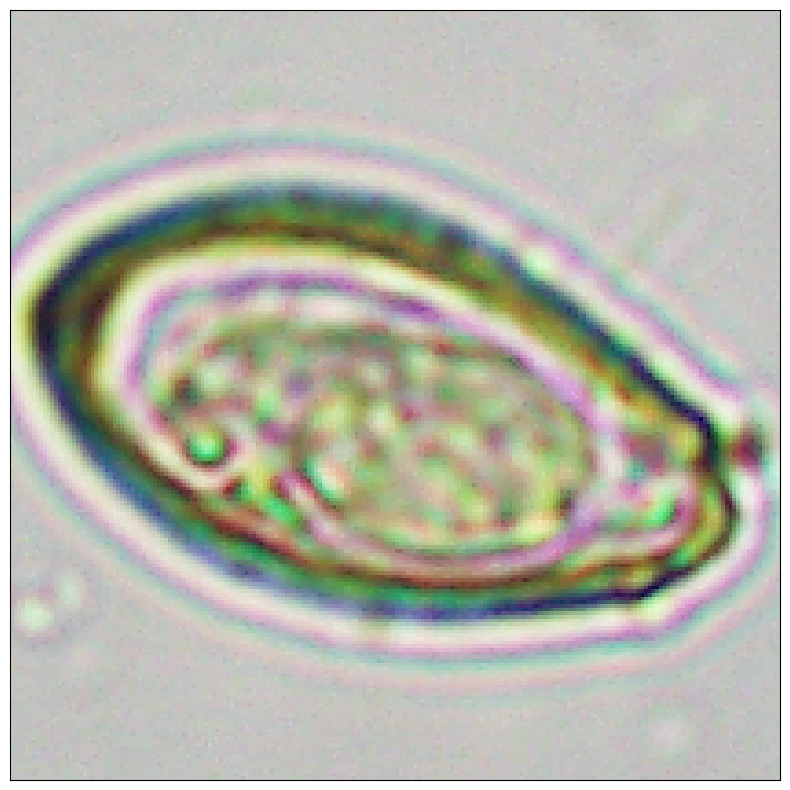

In [ ]:
plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class1[i], cmap = plt.cm.binary)
plt.show()

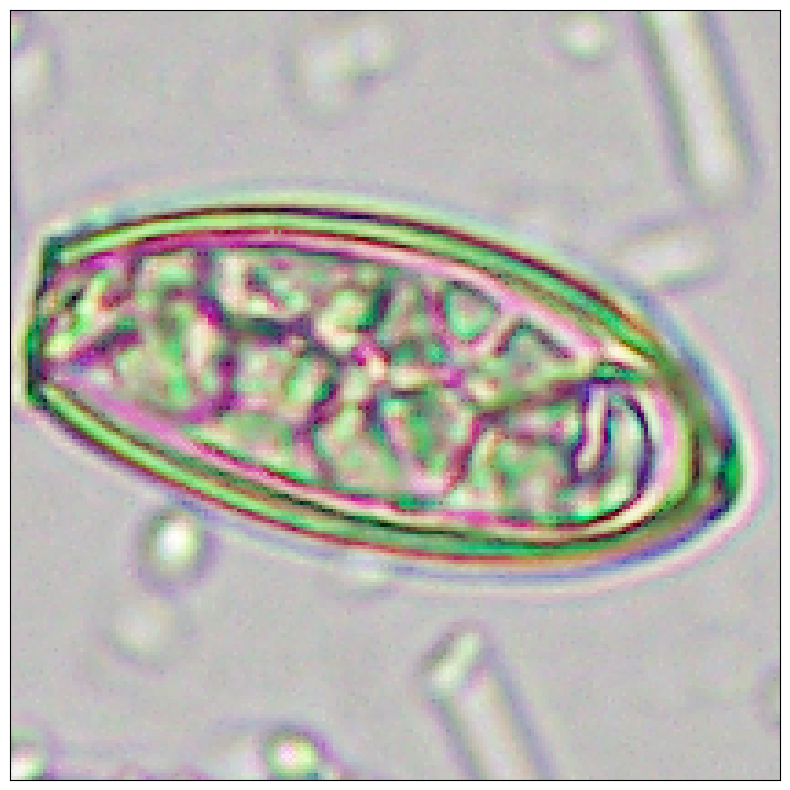

In [ ]:
plt.figure(figsize = (10,10))
for i in range(1):
  plt.subplot(1,1,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(class2[i], cmap = plt.cm.binary)
plt.show()

In [ ]:
print(f"num class0: {len(class0)}")
print(f"num class1: {len(class1)}")
print(f"num class2: {len(class2)}")

num class0: 500
num class1: 500
num class2: 500


Follow Old Route

In [ ]:
class0_label = [0] * len(class0)
class1_label = [1] * len(class1)
class2_label = [2] * len(class2)

In [ ]:
from sklearn.model_selection import train_test_split

x_train_class0, x_test_class0, y_train_class0, y_test_class0 = train_test_split(class0, class0_label, test_size=0.2, random_state=8)
x_train_class1, x_test_class1, y_train_class1, y_test_class1 = train_test_split(class1, class1_label, test_size=0.2, random_state=8)
x_train_class2, x_test_class2, y_train_class2, y_test_class2 = train_test_split(class2, class2_label, test_size=0.2, random_state=8)

In [ ]:
x_train=[]

for i in x_train_class0:
  x_train.append(i)
for i in x_train_class1:
  x_train.append(i)
for i in x_train_class2:
  x_train.append(i)

In [ ]:
x_test=[]

for i in x_test_class0:
  x_test.append(i)
for i in x_test_class1:
  x_test.append(i)
for i in x_test_class2:
  x_test.append(i)

In [ ]:
y_train=[]

for i in y_train_class0:
  y_train.append(i)
for i in y_train_class1:
  y_train.append(i)
for i in y_train_class2:
  y_train.append(i)

In [ ]:
y_test=[]

for i in y_test_class0:
  y_test.append(i)
for i in y_test_class1:
  y_test.append(i)
for i in y_test_class2:
  y_test.append(i)

In [ ]:
print(f"num x_train: {len(x_train)}")
print(f"num x_test: {len(x_test)}")
print(f"num y_train: {len(y_train)}")
print(f"num y_test: {len(y_test)}")

num x_train: 1200
num x_test: 300
num y_train: 1200
num y_test: 300


###Data Augmentation

In [ ]:
from PIL import Image
import numpy as np

def imrotation(img, angle):
  if isinstance(img, np.ndarray):
    img = Image.fromarray(img)

  rotate_img = img.rotate(-angle, expand=False)
  rotate_img = np.array(rotate_img)

  return rotate_img[:, :, 0:3]

In [ ]:
from PIL import ImageEnhance

def brightness(img, value):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  enhancer = ImageEnhance.Brightness(pil_img)
  factor = 1.0 + (value / 255.0)
  brightened_image = enhancer.enhance(factor)

  return np.array(brightened_image)

In [ ]:
def histeq(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  img_float = img_array.astype(np.float32)
  yuv = np.dot(img_float, [[0.299, -0.168736, 0.5], [0.587, -0.331264, -0.418688], [0.114, 0.5, -0.081312]])
  yuv[:,:,1:] += 128.0

  y_channel = yuv[:,:,0].astype(np.uint8)
  pil_y = Image.fromarray(y_channel)
  equalized_y = np.array(pil_y.point(lambda x: _get_equalization_lut()[x]))
  yuv[:,:,0] = equalized_y

  yuv[:,:,1:] -= 128.0
  rgb = np.dot(yuv, [[1.0, 1.0, 1.0], [0.0, -0.394642, 2.03211], [1.13983, -0.58062, 0.0]])
  rgb = np.clip(rgb, 0, 255).astype(np.uint8)

  return Image.fromarray(rgb)

def _get_equalization_lut():
  return list(range(256))

In [ ]:
from PIL import ImageFilter

def averaging(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  image = pil_img.filter(ImageFilter.BoxBlur(2.5))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
def addgaussian(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  r, g, b = img_array[:, :, 0], img_array[:, :, 1], img_array[:, :, 2]

  mean = 0
  sd = 1

  r_noise = np.random.normal(mean, sd, r.shape).astype(np.uint8)
  g_noise = np.random.normal(mean, sd, g.shape).astype(np.uint8)
  b_noise = np.random.normal(mean, sd, b.shape).astype(np.uint8)

  r = np.clip(r.astype(np.int16) + r_noise, 0, 255).astype(np.uint8)
  g = np.clip(g.astype(np.int16) + g_noise, 0, 255).astype(np.uint8)
  b = np.clip(b.astype(np.int16) + b_noise, 0, 255).astype(np.uint8)

  img_array = np.stack([r, g, b], axis=2)
  image = Image.fromarray(img_array)
  return image

In [ ]:
from PIL import Image, ImageFilter
import numpy as np

def sharpening(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  kernel = [-1, -1, -1, -1,  9, -1, -1, -1, -1]

  image = pil_img.filter(ImageFilter.Kernel((3, 3), kernel))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
x_train_temp = []
y_train_temp = []

for i in range(len(x_train)):
  current_img_np = np.array(x_train[i])

  for j in range(0,360,90):
    image_r = imrotation(current_img_np, j)

    x_train_temp.append(image_r)
    y_train_temp.append(y_train[i])

    x_train_temp.append(brightness(image_r, 50))
    y_train_temp.append(y_train[i])

    x_train_temp.append(histeq(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(averaging(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(addgaussian(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(sharpening(image_r))
    y_train_temp.append(y_train[i])

x_train = x_train_temp
y_train = y_train_temp

In [ ]:
print(f"x_train: {len(x_train)}")
print(f"y_train: {len(y_train)}")

x_train: 28800
y_train: 28800


###Model Training and Validation

In [ ]:
from keras.utils import to_categorical

y_train_cat = to_categorical(y_train)

In [ ]:
size = (128,128)

for i in range(len(x_train)):
  if isinstance(x_train[i], np.ndarray):
    x_train[i] = Image.fromarray(x_train[i])
  x_train[i] = x_train[i].resize(size)
  x_train[i] = np.array(x_train[i])

for i in range(len(x_test)):
  if isinstance(x_test[i], np.ndarray):
    x_test[i] = Image.fromarray(x_test[i])
  x_test[i] = x_test[i].resize(size)
  x_test[i] = np.array(x_test[i])

In [ ]:
import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
EPOCH = 50

####Model PACA

In [ ]:
from tensorflow.keras import layers, Model

def conv_block(x, filters, k=3, s=1):
  x = layers.Conv2D(filters, k, strides=s, padding="same", use_bias=False)(x)
  x = layers.BatchNormalization()(x)
  x = layers.Activation("relu")(x)
  return x

def paca_model(img_size):
  inp = layers.Input(shape=(img_size, img_size, 3))

  a = conv_block(inp, 32); a = layers.MaxPool2D()(a)
  a = conv_block(a, 64);  a = layers.MaxPool2D()(a)
  a = conv_block(a, 128); a = layers.MaxPool2D()(a)
  a = conv_block(a, 256)
  a = layers.GlobalAveragePooling2D()(a)

  b = layers.Conv2D(96, kernel_size=4, strides=4, padding="same")(inp)
  b = layers.Reshape((-1, 96))(b)
  b = layers.LayerNormalization()(b)

  attn = layers.MultiHeadAttention(num_heads=4, key_dim=24, dropout=0.1)(b, b)
  b = layers.Add()([b, attn])
  b = layers.LayerNormalization()(b)

  ffn = layers.Dense(192, activation="relu")(b)
  ffn = layers.Dropout(0.1)(ffn)
  ffn = layers.Dense(96)(ffn)
  b = layers.Add()([b, ffn])
  b = layers.LayerNormalization()(b)

  b = layers.GlobalAveragePooling1D()(b)

  x = layers.Concatenate()([a, b])
  x = layers.Dense(256, activation="relu")(x)
  x = layers.Dropout(0.35)(x)
  x = layers.Dense(64, activation="relu")(x)
  x = layers.Dropout(0.25)(x)
  out = layers.Dense(3, activation="sigmoid")(x)

  model = Model(inp, out, name="PACA")
  return model

model = paca_model(x_train[0].shape[0])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 77s 22ms/step - accuracy: 0.9088 - loss: 0.2546 - val_accuracy: 0.6819 - val_loss: 0.5474
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9647 - loss: 0.1084 - val_accuracy: 0.9469 - val_loss: 0.1804
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9791 - loss: 0.0688 - val_accuracy: 0.9628 - val_loss: 0.1104
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9851 - loss: 0.0503 - val_accuracy: 0.9736 - val_loss: 0.0749
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9882 - loss: 0.0383 - val_accuracy: 0.7951 - val_loss: 0.7534
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9894 - loss: 0.0354 - val_accuracy: 0.6969 - val_loss: 1.2594
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9925 - loss: 0.0254 - val_accuracy: 0.7688 - val_loss: 0.5743
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9931 -

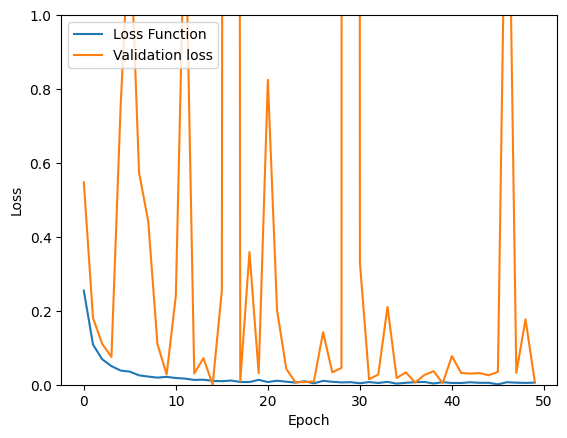

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

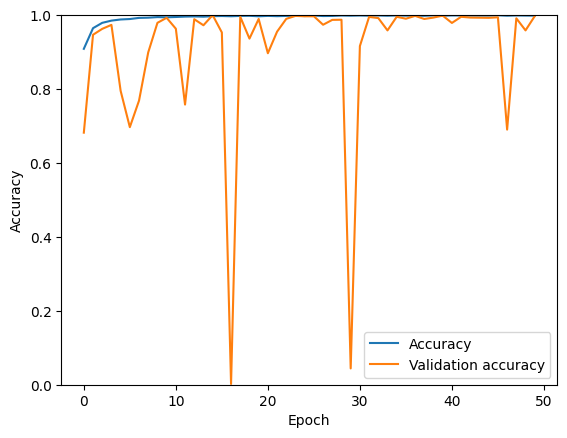

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 407ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[100   0   0]
 [  1  99   0]
 [  1   0  99]]
--------------------------
Accuracy: 0.9933333333333333
Precision: 0.9934640522875816
Recall: 0.9933333333333333
F1 score: 0.9933495862149028


In [ ]:
model.save(path + "paca_d2.keras")

####Model CNN

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential()

model.add(Conv2D(64, (3, 3), activation = 'relu', input_shape = (x_train[0].shape)))
model.add(Conv2D(64, (3, 3), activation = 'relu'))
model.add(Conv2D(64, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(Conv2D(32, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(Conv2D(16, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(Conv2D(8, (3, 3), activation = 'relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(128, activation = 'relu'))
model.add(Dense(64, activation = 'relu'))
model.add(Dense(32, activation = 'relu'))
model.add(Dense(16, activation = 'relu'))
model.add(Dense(8, activation = 'relu'))
model.add(Dense(3, activation = 'sigmoid'))

model.compile(optimizer = 'sgd', loss = 'mse', metrics = ['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model Training

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.3707 - loss: 0.2234 - val_accuracy: 0.0000e+00 - val_loss: 0.2639
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.5181 - loss: 0.2016 - val_accuracy: 0.0000e+00 - val_loss: 0.3652
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.7685 - loss: 0.1044 - val_accuracy: 0.7191 - val_loss: 0.2100
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.8652 - loss: 0.0720 - val_accuracy: 0.6465 - val_loss: 0.1857
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 35s 13ms/step - accuracy: 0.8992 - loss: 0.0518 - val_accuracy: 0.9028 - val_loss: 0.0525
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 36s 14ms/step - accuracy: 0.9265 - loss: 0.0390 - val_accuracy: 0.8729 - val_loss: 0.0654
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.9390 - loss: 0.0322 - val_accuracy: 0.9042 - val_loss: 0.0505
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 36s 14ms/step - accuracy: 

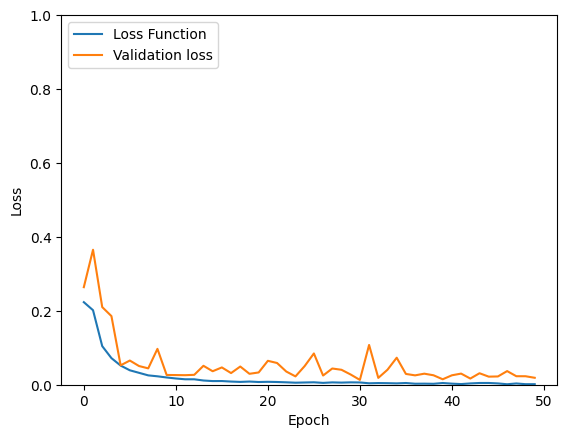

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

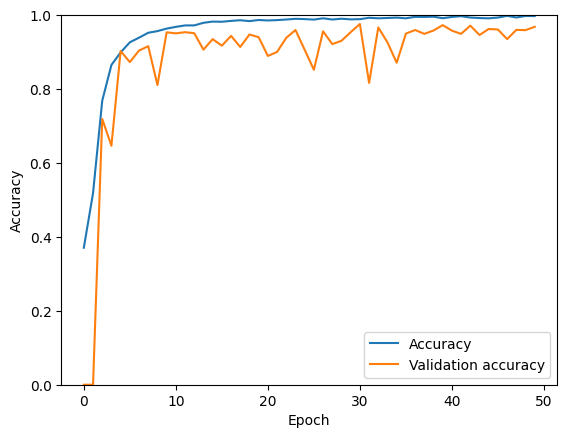

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[100   0   0]
 [  0 100   0]
 [  2   1  97]]
--------------------------
Accuracy: 0.99
Precision: 0.9901637222545784
Recall: 0.99
F1 score: 0.9899651530423138


In [ ]:
model.save(path + "cnn_d2.keras")

##Classification Model with Dataset 1 and 2

###Import Dataset

In [ ]:
import os
from PIL import Image

def loadimages(folder):
  images = []
  for filename in os.listdir(folder):
    img = Image.open(os.path.join(folder,filename))
    if img is not None:
      images.append(img)
  return images

In [ ]:
class0 = loadimages("/content/dataset/class0_d2")
class1 = loadimages("/content/dataset/class1_d2")
class2 = loadimages("/content/dataset/class2_d2")

In [ ]:
print(f"num class0: {len(class0)}")
print(f"num class1: {len(class1)}")
print(f"num class2: {len(class2)}")

num class0: 500
num class1: 500
num class2: 500


In [ ]:
print(f"num class0: {len(class0)}")
print(f"num class1: {len(class1)}")
print(f"num class2: {len(class2)}")

num class0: 500
num class1: 500
num class2: 500


Follow Old Route

In [ ]:
class0_label = [0] * len(class0)
class1_label = [1] * len(class1)
class2_label = [2] * len(class2)

In [ ]:
from sklearn.model_selection import train_test_split

x_train_class0, x_test_class0, y_train_class0, y_test_class0 = train_test_split(class0, class0_label, test_size=0.2, random_state=8)
x_train_class1, x_test_class1, y_train_class1, y_test_class1 = train_test_split(class1, class1_label, test_size=0.2, random_state=8)
x_train_class2, x_test_class2, y_train_class2, y_test_class2 = train_test_split(class2, class2_label, test_size=0.2, random_state=8)

In [ ]:
x_train=[]

for i in x_train_class0:
  x_train.append(i)
for i in x_train_class1:
  x_train.append(i)
for i in x_train_class2:
  x_train.append(i)

In [ ]:
x_test=[]

for i in x_test_class0:
  x_test.append(i)
for i in x_test_class1:
  x_test.append(i)
for i in x_test_class2:
  x_test.append(i)

In [ ]:
y_train=[]

for i in y_train_class0:
  y_train.append(i)
for i in y_train_class1:
  y_train.append(i)
for i in y_train_class2:
  y_train.append(i)

In [ ]:
y_test=[]

for i in y_test_class0:
  y_test.append(i)
for i in y_test_class1:
  y_test.append(i)
for i in y_test_class2:
  y_test.append(i)

In [ ]:
print(f"num x_train: {len(x_train)}")
print(f"num x_test: {len(x_test)}")
print(f"num y_train: {len(y_train)}")
print(f"num y_test: {len(y_test)}")

num x_train: 1200
num x_test: 300
num y_train: 1200
num y_test: 300


###Data Augmentation

In [ ]:
from PIL import Image
import numpy as np

def imrotation(img, angle):
  if isinstance(img, np.ndarray):
    img = Image.fromarray(img)

  rotate_img = img.rotate(-angle, expand=False)
  rotate_img = np.array(rotate_img)

  return rotate_img[:, :, 0:3]

In [ ]:
from PIL import ImageEnhance

def brightness(img, value):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  enhancer = ImageEnhance.Brightness(pil_img)
  factor = 1.0 + (value / 255.0)
  brightened_image = enhancer.enhance(factor)

  return np.array(brightened_image)

In [ ]:
def histeq(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  img_float = img_array.astype(np.float32)
  yuv = np.dot(img_float, [[0.299, -0.168736, 0.5], [0.587, -0.331264, -0.418688], [0.114, 0.5, -0.081312]])
  yuv[:,:,1:] += 128.0

  y_channel = yuv[:,:,0].astype(np.uint8)
  pil_y = Image.fromarray(y_channel)
  equalized_y = np.array(pil_y.point(lambda x: _get_equalization_lut()[x]))
  yuv[:,:,0] = equalized_y

  yuv[:,:,1:] -= 128.0
  rgb = np.dot(yuv, [[1.0, 1.0, 1.0], [0.0, -0.394642, 2.03211], [1.13983, -0.58062, 0.0]])
  rgb = np.clip(rgb, 0, 255).astype(np.uint8)

  return Image.fromarray(rgb)

def _get_equalization_lut():
  return list(range(256))

In [ ]:
from PIL import ImageFilter

def averaging(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  image = pil_img.filter(ImageFilter.BoxBlur(2.5))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
def addgaussian(img):
  if isinstance(img, Image.Image):
    img_array = np.array(img)
  else:
    img_array = img

  r, g, b = img_array[:, :, 0], img_array[:, :, 1], img_array[:, :, 2]

  mean = 0
  sd = 1

  r_noise = np.random.normal(mean, sd, r.shape).astype(np.uint8)
  g_noise = np.random.normal(mean, sd, g.shape).astype(np.uint8)
  b_noise = np.random.normal(mean, sd, b.shape).astype(np.uint8)

  r = np.clip(r.astype(np.int16) + r_noise, 0, 255).astype(np.uint8)
  g = np.clip(g.astype(np.int16) + g_noise, 0, 255).astype(np.uint8)
  b = np.clip(b.astype(np.int16) + b_noise, 0, 255).astype(np.uint8)

  img_array = np.stack([r, g, b], axis=2)
  image = Image.fromarray(img_array)
  return image

In [ ]:
from PIL import Image, ImageFilter
import numpy as np

def sharpening(img):
  if isinstance(img, np.ndarray):
    pil_img = Image.fromarray(img)
  else:
    pil_img = img

  kernel = [-1, -1, -1, -1,  9, -1, -1, -1, -1]

  image = pil_img.filter(ImageFilter.Kernel((3, 3), kernel))
  if isinstance(img, np.ndarray):
      return np.array(image)

  return image

In [ ]:
x_train_temp = []
y_train_temp = []

for i in range(len(x_train)):
  current_img_np = np.array(x_train[i])

  for j in range(0,360,90):
    image_r = imrotation(current_img_np, j)

    x_train_temp.append(image_r)
    y_train_temp.append(y_train[i])

    x_train_temp.append(brightness(image_r, 50))
    y_train_temp.append(y_train[i])

    x_train_temp.append(histeq(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(averaging(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(addgaussian(image_r))
    y_train_temp.append(y_train[i])

    x_train_temp.append(sharpening(image_r))
    y_train_temp.append(y_train[i])

x_train = x_train_temp
y_train = y_train_temp

In [ ]:
print(f"x_train: {len(x_train)}")
print(f"y_train: {len(y_train)}")

x_train: 28800
y_train: 28800


###Model Training and Validation

In [ ]:
from keras.utils import to_categorical

y_train_cat = to_categorical(y_train)

In [ ]:
size = (128,128)

for i in range(len(x_train)):
  if isinstance(x_train[i], np.ndarray):
    x_train[i] = Image.fromarray(x_train[i])
  x_train[i] = x_train[i].resize(size)
  x_train[i] = np.array(x_train[i])

for i in range(len(x_test)):
  if isinstance(x_test[i], np.ndarray):
    x_test[i] = Image.fromarray(x_test[i])
  x_test[i] = x_test[i].resize(size)
  x_test[i] = np.array(x_test[i])

In [ ]:
import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
EPOCH = 50

####Model PACA

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/parasitic_platform/paca_d1.keras")

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 104s 23ms/step - accuracy: 0.9806 - loss: 0.0594 - val_accuracy: 0.9951 - val_loss: 0.0165
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9905 - loss: 0.0245 - val_accuracy: 0.9882 - val_loss: 0.0389
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9911 - loss: 0.0176 - val_accuracy: 0.9271 - val_loss: 0.4520
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9892 - loss: 0.0170 - val_accuracy: 1.0000 - val_loss: 2.0937e-04
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9909 - loss: 0.0147 - val_accuracy: 0.9924 - val_loss: 0.0173
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9911 - loss: 0.0115 - val_accuracy: 0.9903 - val_loss: 0.0242
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 52s 20ms/step - accuracy: 0.9900 - loss: 0.0093 - val_accuracy: 0.9812 - val_loss: 0.0378
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 53s 20ms/step - accuracy: 0.9

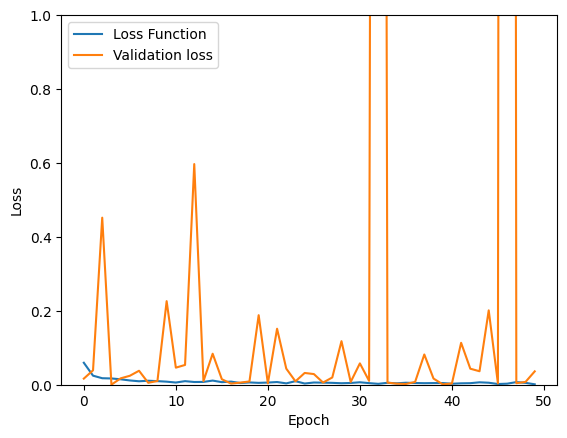

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

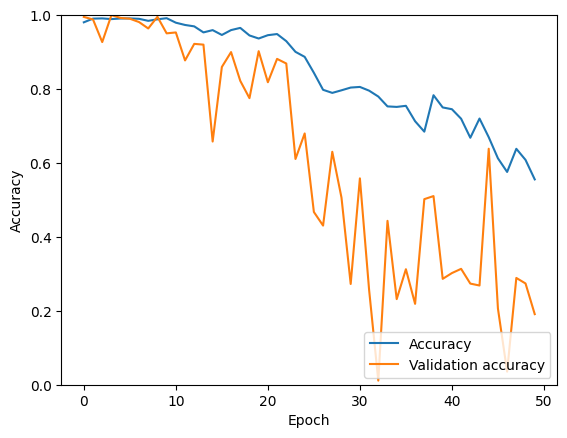

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 935ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[97  3  0]
 [83 16  1]
 [88  0 12]]
--------------------------
Accuracy: 0.4166666666666667
Precision: 0.7090408282474268
Recall: 0.4166666666666667
F1 score: 0.3361569521998873


In [ ]:
model.save(path + "paca_d12.keras")

####Model CNN

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/parasitic_platform/cnn_d1.keras")

Model Training

In [ ]:
history = model.fit(x_train, y_train_cat, epochs = EPOCH, batch_size = 10, validation_split = 0.1)

Epoch 1/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.9431 - loss: 0.0303 - val_accuracy: 0.9597 - val_loss: 0.0213
Epoch 2/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9649 - loss: 0.0186 - val_accuracy: 0.9052 - val_loss: 0.0506
Epoch 3/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9754 - loss: 0.0133 - val_accuracy: 0.9597 - val_loss: 0.0221
Epoch 4/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9803 - loss: 0.0108 - val_accuracy: 0.9233 - val_loss: 0.0407
Epoch 5/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9837 - loss: 0.0089 - val_accuracy: 0.9601 - val_loss: 0.0195
Epoch 6/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9856 - loss: 0.0078 - val_accuracy: 0.9514 - val_loss: 0.0255
Epoch 7/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9881 - loss: 0.0065 - val_accuracy: 0.9628 - val_loss: 0.0196
Epoch 8/50
2592/2592 ━━━━━━━━━━━━━━━━━━━━ 34s 13ms/step - accuracy: 0.9906 -

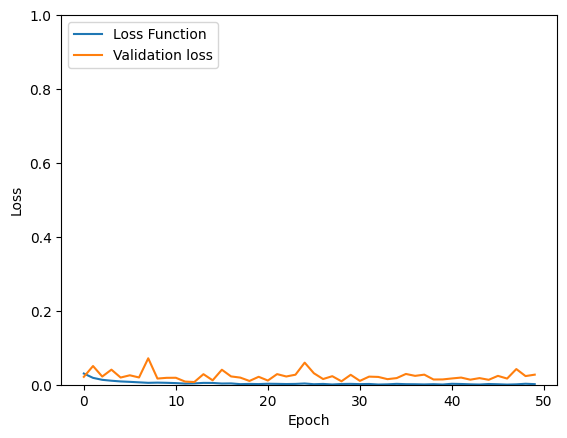

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Loss Function')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 1])
plt.legend(loc='upper left')

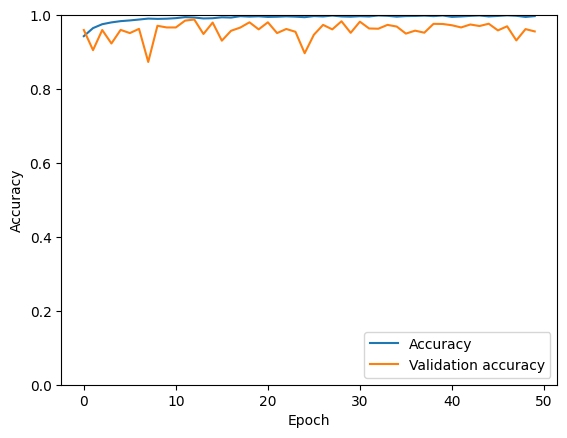

In [ ]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

In [ ]:
y_outp = model.predict(x_test)
y_pred = np.argmax(y_outp, axis=1)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print('--------------------------')
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

Confusion Matrix:
[[98  0  2]
 [ 1 99  0]
 [ 2  2 96]]
--------------------------
Accuracy: 0.9766666666666667
Precision: 0.976695628746548
Recall: 0.9766666666666667
F1 score: 0.9766319915573646


In [ ]:
model.save(path + "cnn_d12.keras")